# M3 — Uji Kasus Sulit, Etika, dan Atribusi | Kelompok 05

**Atribusi:** SEA-VL Indonesian subset (KORIKA-AI/sea-vl_crowdsourcing_id), diturunkan dari SEACrowd/sea-vl_crowdsourcing; Cahyawijaya et al. (2025), *Crowdsource, Crawl, or Generate? Creating SEA-VL, a Multicultural Vision-Language Dataset for Southeast Asia*, ACL. CC BY-SA 4.0: https://creativecommons.org/licenses/by-sa/4.0/. Query kasus sulit: rancangan Peran 4 Kelompok 05.

**Cara menjalankan:** Colab CPU, jalankan dari atas. Sesuaikan DATA_DIR agar menunjuk bundel resmi yang berisi train.csv, val.csv dan images/; bila gambar berupa ZIP, isi IMAGE_ZIP dengan path arsip asli. Output disimpan di OUT_DIR (dapat diubah). Tidak perlu mengunggah manifest atau skrip Peran 4 terpisah. Versi paket aktual dicatat saat eksekusi.

In [1]:
%pip -q install sentence-transformers pandas pillow matplotlib


In [2]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import json, hashlib, time, random, platform, importlib.metadata
import numpy as np
import pandas as pd
import torch
from PIL import Image
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from IPython.display import display
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cpu'
DATA_DIR = Path('/content/drive/MyDrive/MULTIMODAL/bundle-mahasiswa/bundle-mahasiswa')
OUT_DIR = Path('/content/drive/MyDrive/MULTIMODAL/Milestone/M3_Peran3')
OUT_DIR.mkdir(parents=True, exist_ok=True)
# Jika folder gambar tidak tersedia, isi path arsip gambar asli Peran 4.
IMAGE_ZIP = None  # contoh: Path('/content/drive/MyDrive/.../images-20261112T145641Z-1-001.zip')
# Opsional: hasil JSON Peran 4 untuk verifikasi V1.
PERAN4_RESULT = OUT_DIR / 'M3_Peran4_Hasil_Uji_Kasus_Sulit_T05.json'
print('Output:', OUT_DIR)

Mounted at /content/drive
Output: /content/drive/MyDrive/MULTIMODAL/Milestone/M3_Peran3


## 1. Manifest asli Peran 4 (tertanam, tidak perlu upload ulang)

In [3]:
MANIFEST_RAW = '{\n  "judul": "Protokol Uji Kasus Sulit M3 — Kelompok 05",\n  "pemilik_peran": "Jana Rohman Wasiso (Peran 4: Evaluasi dan Uji Kasus Sulit)",\n  "status": "Siap dieksekusi; kolom probabilitas belum diisi sebelum pipeline M2 V1 dijalankan.",\n  "sumber_gambar": {\n    "arsip": "images-20261112T145641Z-1-001.zip",\n    "catatan": "Setiap gambar diperiksa secara visual. ID di bawah adalah path di dalam arsip images/."\n  },\n  "sistem_utama": {\n    "varian": "V1 ensemble ID (greedy, UTAMA)",\n    "alasan": "Dua templat V1 dipilih hanya dengan subset train (seed 0, n=500) dan dicatat sebagai varian utama M2. V2 berstatus eksplorasi karena dirancang setelah melihat validation.",\n    "encoder_gambar": "sentence-transformers/clip-ViT-B-32",\n    "encoder_teks_indonesia": "sentence-transformers/clip-ViT-B-32-multilingual-v1",\n    "templat_v1": [\n      "{}",\n      "ini adalah foto {}"\n    ],\n    "agregasi_teks": "Rata-rata embedding dua templat, lalu L2-normalisasi ulang.",\n    "probabilitas": "Softmax atas dua skor kosinus kandidat dengan skala logit 100; P(benar)+P(pengecoh)=1 pada setiap baris.",\n    "aturan_lulus": "Lolos jika P(benar) > P(pengecoh)."\n  },\n  "larangan_metodologis": [\n    "Tidak mengubah templat, encoder, skala softmax, atau kandidat setelah melihat hasil sepuluh query.",\n    "Tidak memakai test.csv atau split test untuk pemilihan maupun pelaporan M3.",\n    "Hasil V0/V2, bila dicoba Peran 3, hanya analisis pendukung dan tidak menggantikan hasil utama V1."\n  ],\n  "kasus": [\n    {\n      "no": 1,\n      "jenis": ["negasi", "relasi"],\n      "catatan_visual": "Dua rumah adat kayu: satu tampak tanpa orang, satu lagi memiliki beberapa orang di tangga depan.",\n      "query": [\n        {\n          "id": "1A",\n          "teks": "rumah adat kayu yang tidak memiliki orang di tangganya",\n          "benar": "images/svl_140084616.jpg",\n          "pengecoh": "images/svl_147563198.jpg"\n        },\n        {\n          "id": "1B",\n          "teks": "rumah adat beratap rumbia dengan beberapa orang di tangga",\n          "benar": "images/svl_147563198.jpg",\n          "pengecoh": "images/svl_140084616.jpg"\n        }\n      ]\n    },\n    {\n      "no": 2,\n      "jenis": ["atribut", "penanda budaya"],\n      "catatan_visual": "Dua kain batik dengan perbedaan warna, motif, dan cara penyajian gambar.",\n      "query": [\n        {\n          "id": "2A",\n          "teks": "kain batik cokelat bermotif hitam putih yang diletakkan di lantai",\n          "benar": "images/svl_140084373.jpg",\n          "pengecoh": "images/svl_146653588.jpg"\n        },\n        {\n          "id": "2B",\n          "teks": "kain batik merah putih yang sedang dipegang di dalam toko",\n          "benar": "images/svl_146653588.jpg",\n          "pengecoh": "images/svl_140084373.jpg"\n        }\n      ]\n    },\n    {\n      "no": 3,\n      "jenis": ["penanda budaya", "jumlah objek"],\n      "catatan_visual": "Satu orang memainkan instrumen pukul tradisional; gambar pembanding memperlihatkan beberapa pemain angklung.",\n      "query": [\n        {\n          "id": "3A",\n          "teks": "seseorang memainkan alat musik gamelan dengan pemukul",\n          "benar": "images/svl_147562903.jpg",\n          "pengecoh": "images/svl_147562902.jpg"\n        },\n        {\n          "id": "3B",\n          "teks": "sekelompok orang memainkan angklung bambu sambil berdiri",\n          "benar": "images/svl_147562902.jpg",\n          "pengecoh": "images/svl_147562903.jpg"\n        }\n      ]\n    },\n    {\n      "no": 4,\n      "jenis": ["relasi spasial", "atribut"],\n      "catatan_visual": "Kedua gambar memuat perahu nelayan, tetapi berbeda pada warna serta lokasi perahu terhadap pantai atau dermaga.",\n      "query": [\n        {\n          "id": "4A",\n          "teks": "perahu nelayan berwarna warni yang berlabuh di tepi pelabuhan kecil",\n          "benar": "images/svl_147525936.jpg",\n          "pengecoh": "images/svl_146653596.jpg"\n        },\n        {\n          "id": "4B",\n          "teks": "perahu kecil berwarna hijau biru di tepi pantai berpasir",\n          "benar": "images/svl_146653596.jpg",\n          "pengecoh": "images/svl_147525936.jpg"\n        }\n      ]\n    },\n    {\n      "no": 5,\n      "jenis": ["penanda budaya", "atribut", "relasi"],\n      "catatan_visual": "Dua gambar sama-sama menampilkan tokoh bertopeng tradisional, namun berbeda pada jumlah tokoh, warna busana, latar, dan kain yang terlihat.",\n      "query": [\n        {\n          "id": "5A",\n          "teks": "tiga tokoh bertopeng dalam busana merah hitam berdiri di luar ruangan",\n          "benar": "images/svl_141004357.jpg",\n          "pengecoh": "images/svl_141004380.jpg"\n        },\n        {\n          "id": "5B",\n          "teks": "dua tokoh bertopeng di dalam ruangan dengan kain biru menjuntai",\n          "benar": "images/svl_141004380.jpg",\n          "pengecoh": "images/svl_141004357.jpg"\n        }\n      ]\n    }\n  ]\n}\n'
manifest = json.loads(MANIFEST_RAW)
manifest_hash = hashlib.sha256(MANIFEST_RAW.encode()).hexdigest()
rows = [dict(q, case=c['no'], jenis='; '.join(c['jenis'])) for c in manifest['kasus'] for q in c['query']]
assert len(rows)==10 and len({r['id'] for r in rows})==10
for c in manifest['kasus']:
    a,b=c['query']; assert a['benar']==b['pengecoh'] and b['benar']==a['pengecoh']
ids=sorted({r[k] for r in rows for k in ('benar','pengecoh')})
assert len(ids)==10
print('SHA256 manifest:', manifest_hash)
display(pd.DataFrame(rows))

SHA256 manifest: 8b38fb3a42d9796f776b8453e26608f607ac2f4178b1bb7fab2ea347580eaf9c


,id,teks,benar,pengecoh,case,jenis
0,1A,rumah adat kayu yang tidak memiliki orang di t...,images/svl_140084616.jpg,images/svl_147563198.jpg,1,negasi; relasi
1,1B,rumah adat beratap rumbia dengan beberapa oran...,images/svl_147563198.jpg,images/svl_140084616.jpg,1,negasi; relasi
2,2A,kain batik cokelat bermotif hitam putih yang d...,images/svl_140084373.jpg,images/svl_146653588.jpg,2,atribut; penanda budaya
3,2B,kain batik merah putih yang sedang dipegang di...,images/svl_146653588.jpg,images/svl_140084373.jpg,2,atribut; penanda budaya
4,3A,seseorang memainkan alat musik gamelan dengan ...,images/svl_147562903.jpg,images/svl_147562902.jpg,3,penanda budaya; jumlah objek
5,3B,sekelompok orang memainkan angklung bambu samb...,images/svl_147562902.jpg,images/svl_147562903.jpg,3,penanda budaya; jumlah objek
6,4A,perahu nelayan berwarna warni yang berlabuh di...,images/svl_147525936.jpg,images/svl_146653596.jpg,4,relasi spasial; atribut
7,4B,perahu kecil berwarna hijau biru di tepi panta...,images/svl_146653596.jpg,images/svl_147525936.jpg,4,relasi spasial; atribut
8,5A,tiga tokoh bertopeng dalam busana merah hitam ...,images/svl_141004357.jpg,images/svl_141004380.jpg,5,penanda budaya; atribut; relasi
9,5B,dua tokoh bertopeng di dalam ruangan dengan ka...,images/svl_141004380.jpg,images/svl_141004357.jpg,5,penanda budaya; atribut; relasi


## 2. Pemeriksaan sumber gambar dan split
Hanya train/val. Jika kandidat tidak ditemukan pada kedua CSV, eksperimen dihentikan. Kandidat tidak diganti. Pencocokan nama file harus unik per split; jika ID berada pada kedua split, dilaporkan sebagai overlap.

,image,split
0,images/svl_140084373.jpg,val
1,images/svl_140084616.jpg,train
2,images/svl_141004357.jpg,train
3,images/svl_141004380.jpg,train
4,images/svl_146653588.jpg,train
5,images/svl_146653596.jpg,train
6,images/svl_147525936.jpg,train
7,images/svl_147562902.jpg,train
8,images/svl_147562903.jpg,train
9,images/svl_147563198.jpg,train


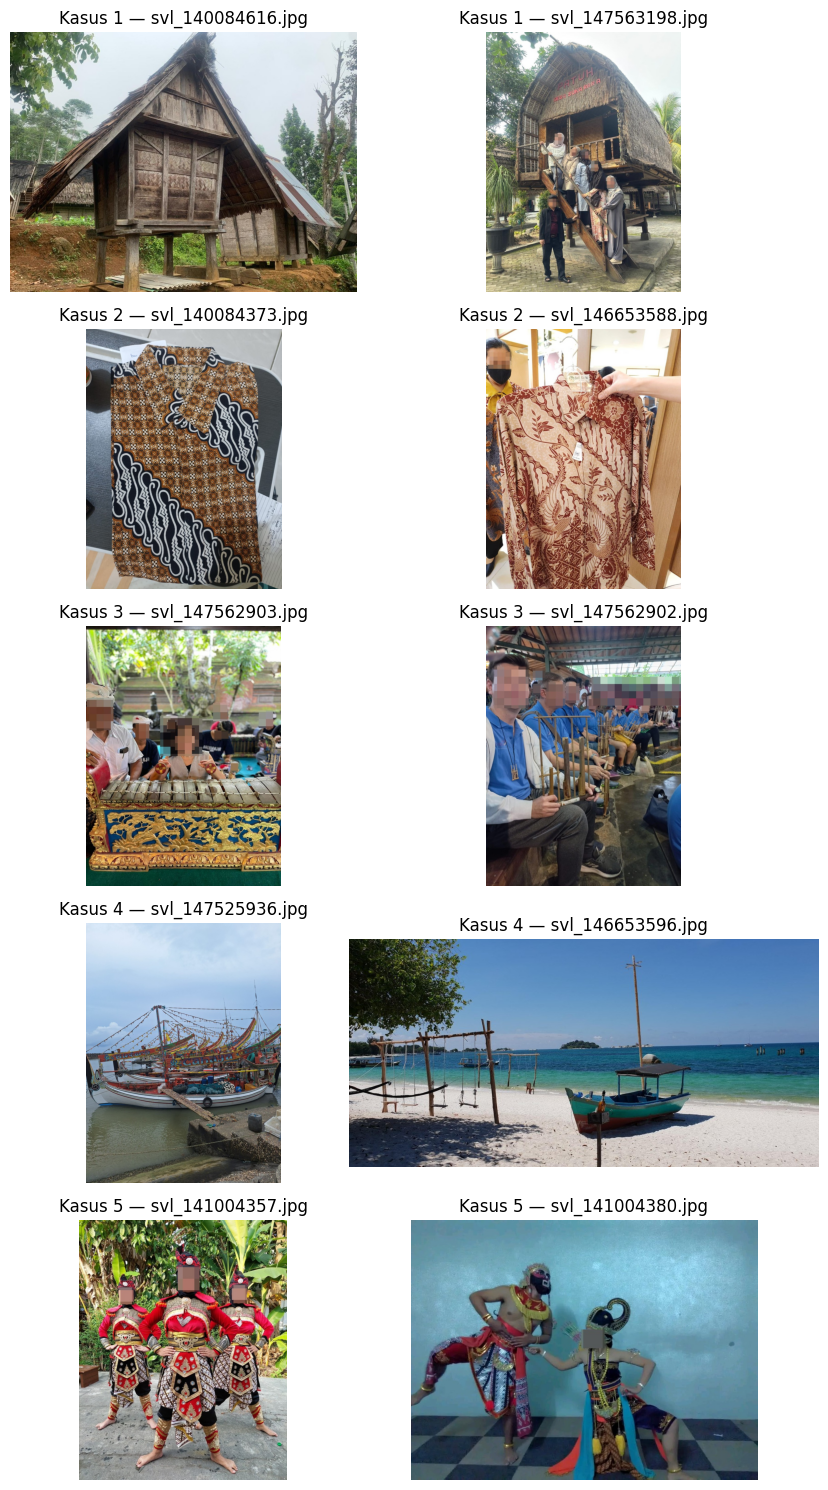

In [4]:
split_index={}
for split in ('train','val'):
    df=pd.read_csv(DATA_DIR / f'{split}.csv')
    assert 'file' in df.columns
    for f in df['file'].dropna().astype(str):
        key=Path(f.replace(chr(92),'/')).name
        split_index.setdefault(key,{}).setdefault(split,set()).add(f)
provenance={}
for i in ids:
    matches=split_index.get(Path(i).name,{})
    if not matches: raise ValueError(f'{i} tidak terdaftar pada train/val. Hubungi Peran 4; jangan ganti kandidat.')
    if any(len(v)>1 for v in matches.values()): raise ValueError(f'Path ambigu: {i}')
    provenance[i]=';'.join(sorted(matches))
display(pd.DataFrame([{'image':i,'split':provenance[i]} for i in ids]))
images={}; image_hashes={}
for i in ids:
    if IMAGE_ZIP is not None:
        with ZipFile(IMAGE_ZIP) as archive: data=archive.read(i)
    else:
        path=DATA_DIR / i
        if not path.is_file(): raise FileNotFoundError(f'{path} tidak ditemukan; atur DATA_DIR atau IMAGE_ZIP asli.')
        data=path.read_bytes()
    image_hashes[i]=hashlib.sha256(data).hexdigest()
    with Image.open(BytesIO(data)) as im: images[i]=im.convert('RGB')
fig,ax=plt.subplots(5,2,figsize=(9,15))
for j,c in enumerate(manifest['kasus']):
    for k,key in enumerate(('benar','pengecoh')):
        i=c['query'][0][key]; ax[j,k].imshow(images[i]); ax[j,k].set_title(f"Kasus {c['no']} — {Path(i).name}"); ax[j,k].axis('off')
plt.tight_layout(); plt.show()

## 3. Konfigurasi M2 dan frozen encoder
Fungsi ensemble disalin dari notebook M2. V0 memakai encoding query asli tanpa agregasi ulang. K1 tidak dipakai karena query seluruhnya Indonesia.

In [5]:
TEMPLATES_ID = [
    "{}", "foto {}", "sebuah foto {}", "gambar {}", "foto budaya Indonesia: {}",
    "dokumentasi budaya Indonesia: {}", "{} di Indonesia", "sebuah foto yang menunjukkan {}",
    "potret {}", "ini adalah foto {}",
]
def l2norm(x):
    return x / np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), 1e-12)

def apply_template(tpl, text, lower_first=True):
    if lower_first and tpl != "{}" and text and text[0].isupper() and not text[:2].isupper():
        text = text[0].lower() + text[1:]
    return tpl.format(text)

def encode_ensemble(encoder, texts, templates, batch_size=64, lower_first=True):
    """Rata-rata embedding teks di bawah tiap templat, lalu normalisasi ulang."""
    outs = []
    for tpl in templates:
        wrapped = [apply_template(tpl, t, lower_first) for t in texts]
        outs.append(np.asarray(encoder.encode(wrapped, batch_size=batch_size, normalize_embeddings=True)))
    return l2norm(np.mean(outs, axis=0))


TEMPLATES = {'V0':['{}'], 'V1': ['{}', 'ini adalah foto {}'], 'V2':TEMPLATES_ID}
assert TEMPLATES['V1']==manifest['sistem_utama']['templat_v1']
SCALE=100.0
MODEL_IMG=manifest['sistem_utama']['encoder_gambar']
MODEL_TXT=manifest['sistem_utama']['encoder_teks_indonesia']
t=time.perf_counter()
img_enc=SentenceTransformer(MODEL_IMG,device=DEVICE)
txt_enc=SentenceTransformer(MODEL_TXT,device=DEVICE)
for enc in (img_enc,txt_enc):
    enc.eval(); enc.requires_grad_(False)
load_seconds=time.perf_counter()-t
print(TEMPLATES)

modules.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

0_CLIPModel/model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

0_CLIPModel/model.safetensors: downloading bytes:           |  0.00B            

... (19 outputs left out)

config.json:   0%|          | 0.00/115 [00:00<?, ?B/s]

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.57MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

{'V0': ['{}'], 'V1': ['{}', 'ini adalah foto {}'], 'V2': ['{}', 'foto {}', 'sebuah foto {}', 'gambar {}', 'foto budaya Indonesia: {}', 'dokumentasi budaya Indonesia: {}', '{} di Indonesia', 'sebuah foto yang menunjukkan {}', 'potret {}', 'ini adalah foto {}']}


In [6]:
t=time.perf_counter()
with torch.inference_mode():
    image_emb=np.asarray(img_enc.encode([images[i] for i in ids],batch_size=16,normalize_embeddings=True))
image_seconds=time.perf_counter()-t
assert np.isfinite(image_emb).all() and np.allclose(np.linalg.norm(image_emb,axis=1),1,atol=1e-5)
emb_by_id=dict(zip(ids,image_emb))
print('Image embeddings:', image_emb.shape)

Image embeddings: (10, 512)


## 4. Eksekusi tiga varian
Skor dan probabilitas mengikuti Peran 4: softmax(100 × cosine) atas dua kandidat. Seri tidak lolos. Waktu encoding diukur satu kali per varian; bukan benchmark latency yang stabil.

V1 mengikuti fungsi `encode_v1` dan `softmax_pair` pada skrip Peran 4; pemuatan model dan gambar dibagi dengan eksperimen Peran 3 untuk menghindari duplikasi. Tabel utama V1 disajikan tersendiri pada bagian 8.

In [7]:
def softmax_pair(q,candidates):
    cos=candidates @ q
    z=SCALE*cos; z=z-z.max(); exp=np.exp(z)
    return exp/exp.sum(),cos
# Sanity test numerik (bukan hasil model)
p,c=softmax_pair(np.array([1.,0.]),np.array([[1.,0.],[0.,1.]]))
assert np.isclose(p.sum(),1) and p[0]>p[1]
texts=[r['teks'] for r in rows]; results=[]; timings={}
for variant,templates in TEMPLATES.items():
    print('Encoding',variant,flush=True); t=time.perf_counter()
    with torch.inference_mode():
        if variant=='V0': q_emb=np.asarray(txt_enc.encode(texts,batch_size=64,normalize_embeddings=True))
        else: q_emb=encode_ensemble(txt_enc,texts,templates)
    timings[variant]=time.perf_counter()-t
    assert np.isfinite(q_emb).all() and np.allclose(np.linalg.norm(q_emb,axis=1),1,atol=1e-5)
    for r,q in zip(rows,q_emb):
        p,c=softmax_pair(q,np.vstack([emb_by_id[r[k]] for k in ('benar','pengecoh')]))
        assert np.isfinite(p).all() and np.isclose(p.sum(),1)
        results.append(dict(variant=variant,id=r['id'],case=r['case'],jenis=r['jenis'],query=r['teks'],correct_image=r['benar'],distractor_image=r['pengecoh'],correct_split=provenance[r['benar']],distractor_split=provenance[r['pengecoh']],cosine_correct=float(c[0]),cosine_distractor=float(c[1]),p_correct=float(p[0]),p_distractor=float(p[1]),margin=float(c[0]-c[1]),passed=bool(p[0]>p[1])))
res=pd.DataFrame(results)
assert len(res)==30 and not res.duplicated(['variant','id']).any()
display(res[['variant','id','cosine_correct','cosine_distractor','p_correct','p_distractor','margin','passed']])

Encoding V0
Encoding V1
Encoding V2


,variant,id,cosine_correct,cosine_distractor,p_correct,p_distractor,margin,passed
0,V0,1A,0.301822,0.280782,0.891288,0.108712,0.021040,True
1,V0,1B,0.262869,0.248401,0.809507,0.190493,0.014468,True
2,V0,2A,0.290457,0.223996,0.998703,0.001297,0.066462,True
3,V0,2B,0.248867,0.240083,0.706505,0.293495,0.008785,True
4,V0,3A,0.271986,0.253562,0.863232,0.136768,0.018424,True
5,V0,3B,0.304068,0.274321,0.951415,0.048585,0.029746,True
6,V0,4A,0.317901,0.260326,0.996851,0.003149,0.057574,True
7,V0,4B,0.280069,0.267421,0.779851,0.220149,0.012648,True
8,V0,5A,0.271958,0.254677,0.849170,0.150830,0.017281,True
9,V0,5B,0.231004,0.177971,0.995050,0.004950,0.053033,True


## 5. Analisis kuantitatif
Pair success = A dan B sama-sama lolos. Improvement/regression dibanding V0 menggunakan query yang sama. Jenis kasus bertumpang tindih; tidak mengisolasi satu atribut. Hasil 10 query tidak mewakili performa seluruh dataset.

In [8]:
summary=[]; base=res[res.variant=='V0'].set_index('id').passed
for v,g in res.groupby('variant',sort=False):
    passed=g.set_index('id').passed.reindex(base.index)
    summary.append(dict(variant=v,templates=len(TEMPLATES[v]),query_pass=int(passed.sum()),query_fail=int((~passed).sum()),query_success=float(passed.mean()),pair_pass=int(g.groupby('case').passed.all().sum()),pair_success=float(g.groupby('case').passed.all().mean()),mean_p_correct=float(g.p_correct.mean()),mean_margin=float(g.margin.mean()),improvement_vs_V0=int((~base & passed).sum()),regression_vs_V0=int((base & ~passed).sum()),encoding_seconds=timings[v],text_encodings=len(texts)*len(TEMPLATES[v])))
summary=pd.DataFrame(summary)
wide=res.pivot(index=['case','id','jenis'],columns='variant',values=['p_correct','margin','passed'])
wide.columns=[f'{a}_{b}' for a,b in wide.columns]; wide=wide.reset_index()
for v in ('V1','V2'):
    wide[f'delta_margin_{v}_vs_V0']=wide[f'margin_{v}']-wide.margin_V0
wide['delta_margin_V2_vs_V1']=wide.margin_V2-wide.margin_V1
display(summary); display(wide)
for v in ('V1','V2'):
    g=res[res.variant==v].set_index('id').passed.reindex(base.index)
    print(v,'perbaikan:',list(base.index[~base & g]),'regresi:',list(base.index[base & ~g]))

,variant,templates,query_pass,query_fail,query_success,pair_pass,pair_success,mean_p_correct,mean_margin,improvement_vs_V0,regression_vs_V0,encoding_seconds,text_encodings
0,V0,1,10,0,1.0,5,1.0,0.884157,0.029946,0,0,0.321763,10
1,V1,2,10,0,1.0,5,1.0,0.896443,0.030692,0,0,0.615942,20
2,V2,10,10,0,1.0,5,1.0,0.926913,0.034848,0,0,3.149861,100


,case,id,jenis,p_correct_V0,p_correct_V1,p_correct_V2,margin_V0,margin_V1,margin_V2,passed_V0,passed_V1,passed_V2,delta_margin_V1_vs_V0,delta_margin_V2_vs_V0,delta_margin_V2_vs_V1
0,1,1A,negasi; relasi,0.891288,0.908973,0.852443,0.02104,0.023012,0.017539,True,True,True,0.001972,-0.003501,-0.005473
1,1,1B,negasi; relasi,0.809507,0.815264,0.940147,0.014468,0.014846,0.027541,True,True,True,0.000378,0.013073,0.012696
2,2,2A,atribut; penanda budaya,0.998703,0.998444,0.998388,0.066462,0.06464,0.064287,True,True,True,-0.001822,-0.002175,-0.000353
3,2,2B,atribut; penanda budaya,0.706505,0.739036,0.874097,0.008785,0.01041,0.019377,True,True,True,0.001625,0.010592,0.008967
4,3,3A,penanda budaya; jumlah objek,0.863232,0.82313,0.957636,0.018424,0.015377,0.031182,True,True,True,-0.003047,0.012758,0.015805
5,3,3B,penanda budaya; jumlah objek,0.951415,0.979642,0.965065,0.029746,0.038737,0.033187,True,True,True,0.008991,0.00344,-0.00555
6,4,4A,relasi spasial; atribut,0.996851,0.996566,0.999003,0.057574,0.056706,0.069094,True,True,True,-0.000868,0.01152,0.012388
7,4,4B,relasi spasial; atribut,0.779851,0.815911,0.735875,0.012648,0.014889,0.010246,True,True,True,0.002241,-0.002402,-0.004643
8,5,5A,penanda budaya; atribut; relasi,0.84917,0.896758,0.957639,0.017281,0.021617,0.031182,True,True,True,0.004336,0.013901,0.009565
9,5,5B,penanda budaya; atribut; relasi,0.99505,0.990706,0.988843,0.053033,0.04669,0.044845,True,True,True,-0.006343,-0.008189,-0.001846


V1 perbaikan: [] regresi: []
V2 perbaikan: [] regresi: []


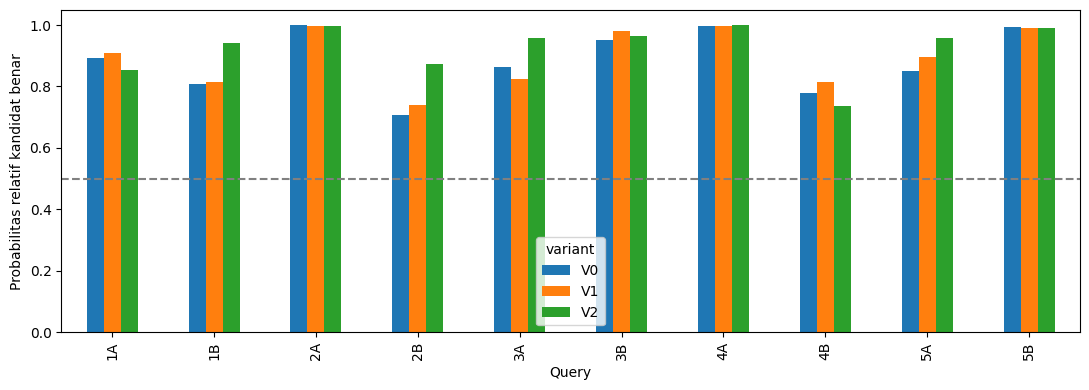

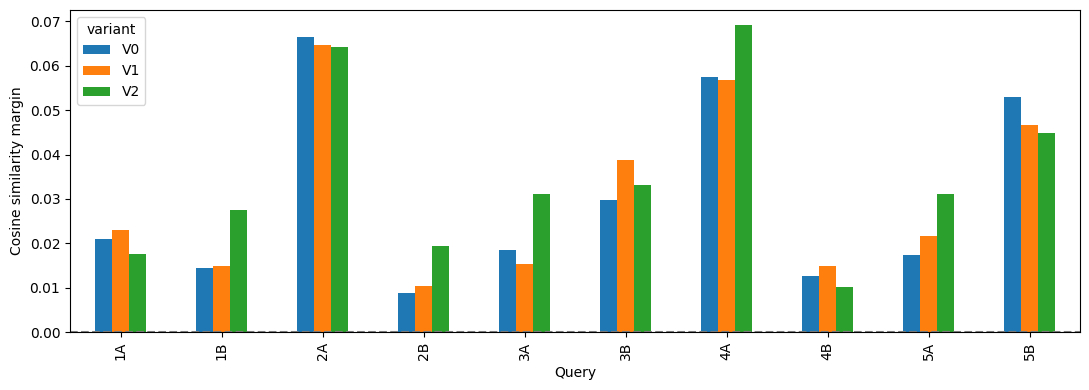

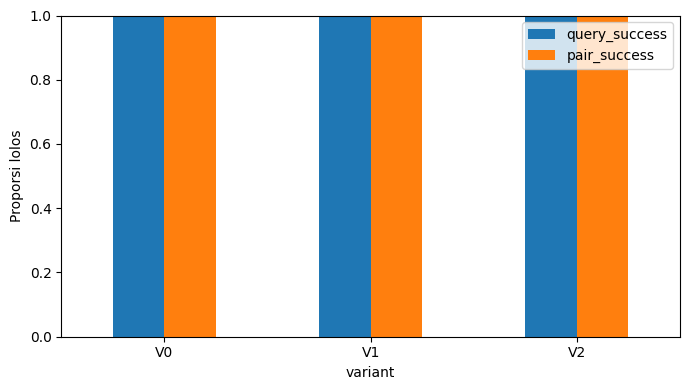

In [9]:
for metric,label in [('p_correct','Probabilitas relatif kandidat benar'),('margin','Cosine similarity margin')]:
    ax=res.pivot(index='id',columns='variant',values=metric).plot.bar(figsize=(11,4))
    ax.axhline(.5 if metric=='p_correct' else 0,linestyle='--',color='gray'); ax.set_ylabel(label); ax.set_xlabel('Query'); plt.tight_layout(); plt.show()
ax=summary.set_index('variant')[['query_success','pair_success']].plot.bar(rot=0,ylim=(0,1),figsize=(7,4)); ax.set_ylabel('Proporsi lolos'); plt.tight_layout(); plt.show()

## 6. Verifikasi opsional terhadap output V1 Peran 4
Tidak mengubah hasil utama. Bila terdapat perbedaan, periksa versi model, paket dan bytes gambar. Toleransi numerik absolut: 1e-5 cosine, 1e-4 probabilitas; status harus identik.

In [10]:
verification={'status':'belum tersedia'}
if PERAN4_RESULT.is_file():
    ref=pd.DataFrame(json.loads(PERAN4_RESULT.read_text())['results']).set_index('id')
    own=res[res.variant=='V1'].set_index('id')
    assert ref.index.is_unique and set(ref.index)==set(own.index)
    ref=ref.reindex(own.index)
    for k in ('query','correct_image','distractor_image'):
        assert ref[k].equals(own[k]),f'Mismatch manifest: {k}'
    errors={k:float((ref[k]-own[k]).abs().max()) for k in ('cosine_correct','cosine_distractor','p_correct','p_distractor')}
    same=bool((ref['pass']==own.passed).all())
    ok=same and all(v<=(1e-5 if k.startswith('cosine') else 1e-4) for k,v in errors.items())
    verification=dict(status='sesuai' if ok else 'perlu investigasi',max_abs_errors=errors,pass_agreement=same)
print(verification)

{'status': 'belum tersedia'}


## 7. Ekspor bukti dan ringkasan otomatis
Ringkasan awal berbasis angka nyata; interpretasi substantif Peran 3 diselesaikan setelah hasil diperoleh. Probabilitas bukan confidence terkalibrasi. Jangan memilih varian utama berdasarkan 10 query.

In [11]:
prefix='M3_Peran3_'
res.to_csv(OUT_DIR/f'{prefix}Hasil_T05.csv',index=False)
wide.to_csv(OUT_DIR/f'{prefix}Perbandingan_Query_T05.csv',index=False)
summary.to_csv(OUT_DIR/f'{prefix}Ringkasan_T05.csv',index=False)
meta=dict(seed=SEED,device=DEVICE,manifest_sha256=manifest_hash,image_sha256=image_hashes,image_split=provenance,models={'image':MODEL_IMG,'text':MODEL_TXT},templates=TEMPLATES,softmax_scale=SCALE,parameter_dilatih=0,load_seconds=load_seconds,image_encoding_seconds=image_seconds,python=platform.python_version(),packages={p:importlib.metadata.version(p) for p in ['sentence-transformers','torch','numpy','pandas','pillow','transformers']},verification_V1=verification,summary=summary.to_dict('records'))
(OUT_DIR/f'{prefix}Ringkasan_Metrik_T05.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8')
(OUT_DIR/'M3_Peran4_Protokol_Kasus_Sulit_T05.json').write_bytes(MANIFEST_RAW.encode())
lines=['# Ringkasan eksperimen Peran 3 — T05','', 'Hasil eksekusi pada 10 query, 5 pasangan; V1 tetap sistem utama.', '']
for r in summary.itertuples():
    lines.append(f'- {r.variant}: {r.query_pass}/10 query, {r.pair_pass}/5 pasangan; mean margin {r.mean_margin:.6f}; perbaikan vs V0 {r.improvement_vs_V0}, regresi {r.regression_vs_V0}; encoding {r.encoding_seconds:.3f} detik.')
lines += ['', 'Verifikasi V1: '+verification['status'], '', 'Limitasi: kandidat hanya dua, softmax skala 100 tidak terkalibrasi; atribut kasus berubah bersamaan; V1/V2 berbeda jumlah dan komposisi templat; V2 eksploratif. Tidak ada klaim generalisasi.','', 'Data: SEA-VL Indonesian subset, Cahyawijaya et al. (2025), CC BY-SA 4.0 — https://creativecommons.org/licenses/by-sa/4.0/.']
(OUT_DIR/f'{prefix}Ringkasan_Awal_T05.md').write_text('\n'.join(lines),encoding='utf-8')
print('Output tersimpan:',OUT_DIR)
for p in sorted(OUT_DIR.glob('M3_Peran3_*')): print(p.name)

Output tersimpan: /content/drive/MyDrive/MULTIMODAL/Milestone/M3_Peran3
M3_Peran3_Hasil_T05.csv
M3_Peran3_Perbandingan_Query_T05.csv
M3_Peran3_Ringkasan_Awal_T05.md
M3_Peran3_Ringkasan_Metrik_T05.json
M3_Peran3_Ringkasan_T05.csv


## 8. Tabel hasil utama M3 — Peran 4 (V1)
Tabel ini menggunakan hasil inference V1 dari pipeline bersama, bukan hasil run independen skrip Peran 4. Output tambahan yang tersimpan dihitung dari CSV asli Peran 3; saat Run all, tabel dan ekspor akan dibentuk dari inference baru.

In [12]:
# Hasil utama kelompok: hanya V1, sesuai protokol Peran 4.
main_v1 = res.loc[res['variant'].eq('V1')].copy().sort_values('id')
assert len(main_v1) == 10 and main_v1['id'].is_unique
cols = ['id', 'query', 'correct_image', 'distractor_image', 'cosine_correct',
        'cosine_distractor', 'p_correct', 'p_distractor', 'margin', 'passed']
main_v1 = main_v1[cols]
display(main_v1.round(4))
print(f"V1: {int(main_v1.passed.sum())}/10 lolos; mean P(benar) = {main_v1.p_correct.mean():.4f}; mean margin = {main_v1.margin.mean():.4f}")
main_v1.to_csv(OUT_DIR / 'M3_Hasil_Utama_V1_T05.csv', index=False)
main_json = {
    'title': 'Hasil utama M3 Kelompok 05 — V1',
    'source_data_attribution': 'SEA-VL Indonesian subset, Cahyawijaya et al. (2025), CC BY-SA 4.0',
    'source_manifest_sha256': manifest_hash,
    'system': {'variant': 'V1', 'image_encoder': MODEL_IMG, 'text_encoder': MODEL_TXT,
               'templates': TEMPLATES['V1'], 'softmax_scale': SCALE,
               'pass_rule': 'p_correct > p_distractor'},
    'results': main_v1.rename(columns={'passed': 'pass'}).to_dict('records')
}
(OUT_DIR / 'M3_Hasil_Utama_V1_T05.json').write_text(json.dumps(main_json, ensure_ascii=False, indent=2), encoding='utf-8')
print('Tabel utama V1 dan JSON disiapkan.')

,id,query,correct_image,distractor_image,cosine_correct,cosine_distractor,p_correct,p_distractor,margin,passed
10,1A,rumah adat kayu yang tidak memiliki orang di t...,images/svl_140084616.jpg,images/svl_147563198.jpg,0.2971,0.2741,0.9090,0.0910,0.0230,True
11,1B,rumah adat beratap rumbia dengan beberapa oran...,images/svl_147563198.jpg,images/svl_140084616.jpg,0.2606,0.2458,0.8153,0.1847,0.0148,True
12,2A,kain batik cokelat bermotif hitam putih yang d...,images/svl_140084373.jpg,images/svl_146653588.jpg,0.2906,0.2260,0.9984,0.0016,0.0646,True
13,2B,kain batik merah putih yang sedang dipegang di...,images/svl_146653588.jpg,images/svl_140084373.jpg,0.2581,0.2477,0.7390,0.2610,0.0104,True
14,3A,seseorang memainkan alat musik gamelan dengan ...,images/svl_147562903.jpg,images/svl_147562902.jpg,0.2781,0.2627,0.8231,0.1769,0.0154,True
15,3B,sekelompok orang memainkan angklung bambu samb...,images/svl_147562902.jpg,images/svl_147562903.jpg,0.3157,0.2770,0.9796,0.0204,0.0387,True
16,4A,perahu nelayan berwarna warni yang berlabuh di...,images/svl_147525936.jpg,images/svl_146653596.jpg,0.3129,0.2562,0.9966,0.0034,0.0567,True
17,4B,perahu kecil berwarna hijau biru di tepi panta...,images/svl_146653596.jpg,images/svl_147525936.jpg,0.2761,0.2612,0.8159,0.1841,0.0149,True
18,5A,tiga tokoh bertopeng dalam busana merah hitam ...,images/svl_141004357.jpg,images/svl_141004380.jpg,0.2680,0.2464,0.8968,0.1032,0.0216,True
19,5B,dua tokoh bertopeng di dalam ruangan dengan ka...,images/svl_141004380.jpg,images/svl_141004357.jpg,0.2274,0.1807,0.9907,0.0093,0.0467,True


V1: 10/10 lolos; mean P(benar) = 0.8964; mean margin = 0.0307
Tabel utama V1 dan JSON disiapkan.


## 9. Interpretasi hasil dan batasan
Pada eksekusi asli, seluruh varian lolos 10/10 query dan 5/5 pasangan. V1 meningkatkan mean margin dari 0,0299 (V0) menjadi 0,0307; V2 mencapai 0,0348 tetapi tetap eksploratif. Tidak terjadi peningkatan tingkat kelulusan karena seluruh varian sudah mencapai 100%. Jumlah dan komposisi templat berbeda sehingga efek jumlah saja tidak terisolasi. Pada V1, 2B memiliki margin terendah sekitar 0,0104. Softmax skala 100 atas dua kandidat bukan confidence terkalibrasi. Sembilan dari sepuluh gambar berasal dari train, beberapa atribut berubah bersamaan, dan tidak tersedia kontrol objek tunggal yang terisolasi. Hasil ini bukan bukti generalisasi atau pemahaman negasi dan relasi secara mendalam. Angka paragraf ini merujuk pada eksekusi asli; jika menjalankan ulang, periksa kesesuaiannya dengan output baru.

Pernyataan etika lengkap disertakan di PDF laporan, bukan pengganti bagian tersebut. Data dan hasil turunan data yang dibagikan mengikuti CC BY-SA 4.0.